# Ordinary Linear Least Squares

Ordinary least squares (OLS) is the most common estimator. OLS estimates are commonly used to analyze both experimental and observational data. The OLS method minimizes the sum of squared residuals, and leads to a closed-form expression for the estimated value of the unknown parameter vector $\beta$:

$$
  \hat{\boldsymbol\beta} = (\mathbf{X}^\mathsf{T}\mathbf{X})^{-1} \mathbf{X}^\mathsf{T} \mathbf{y},
$$

where $\mathbf{y}$ is a vector whose ''i''th element is the ''i''th observation of the dependent variable, and $\mathbf{X}$ is a matrix whose ''ij'' element is the ''i''th observation of the ''j''th independent variable. Let's be more explicit about what each of these variables are, say the true trend in our data can be modelled by:

$$
f(x, \beta) = \sum_{j = 1}^m \beta_j \phi_j(x)
$$

where $\phi_j$ is an arbtrary function of $x$. Well then all we need to to specify what the $\phi_j$'s are and then we can approximate what all of the $\beta_j$'s are. So if the $x_i$'s are our data then the matrix $\mathbf{X}$ from above is constructed as $X_{ij}= \phi_j(x_{i})$

In [2]:
"""
IMPORTS
"""
import numpy as np
import matplotlib.pyplot as plt

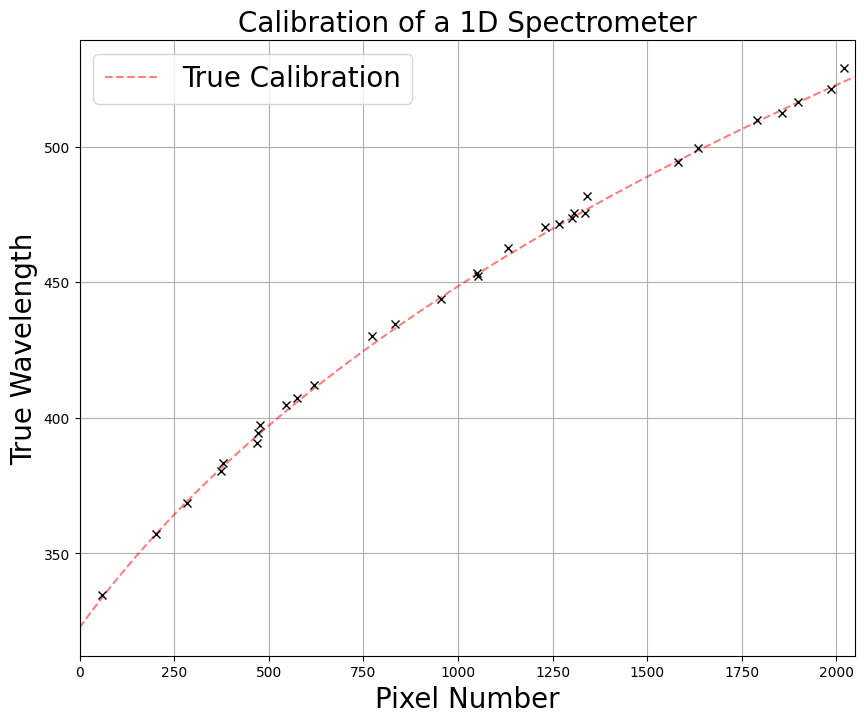

In [3]:
#Define the true underlying data and calibration
pixel_number = np.arange(2048)
calibration = 50*(pixel_number + 500) ** 0.3

NUM_DATA_POINTS = 30
NOISE_LEVEL = 2 #Your measurement error in nm

#Select a random sample of data points from the true calibration
data_x = np.random.choice(pixel_number, size = NUM_DATA_POINTS)
data_y = calibration[data_x] + np.random.normal(0, NOISE_LEVEL, data_x.size).reshape(data_x.shape)

#Plot the underlying data
plt.figure(figsize = (10,8))
plt.plot(pixel_number, calibration, '--', color = 'r', alpha = 0.5, label = 'True Calibration')
plt.plot(data_x, data_y, 'x', color = 'k')
plt.grid()
plt.xlabel("Pixel Number", size = 20)
plt.ylabel("True Wavelength", size = 20)
plt.title("Calibration of a 1D Spectrometer", size = 20)
plt.legend(prop={'size': 20})
plt.xlim(0, 2048)
plt.show()

Here are the equivalent plots from when I did this lab when I was in 3rd year. You can see that my axis lables were way too small also!

![title](hydrogen.png)
![title](calibration.png)

The unkown in our problem is the specific calibration function that connects all of our dots. Essentially, we need an approximation for the red curve above. For this method, we are going to assume that our solution can be well approximated by a polynomial and then use the OLS method to figure out the coefficients of your polynomial. We are going to try a variety of fits where we keep adding an extra polynomial. The trick will be not overplotting. 

0.10x + 344.83
-2.87E-05x**2 + 0.15x + 326.06
7.29E-09x**3 + -5.08E-05x**2 + 0.17x + 322.79


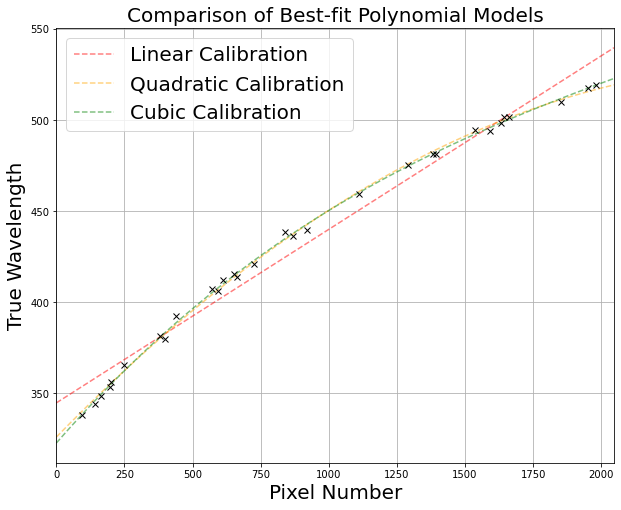

In [3]:
#Lets start by setting up our model matrices for each of the polynomial fits
X_lin = np.array([data_x, np.ones(data_x.size)]).T
X_quad = np.array([data_x**2, data_x, np.ones(data_x.size)]).T
X_cube = np.array([data_x**3, data_x**2, data_x, np.ones(data_x.size)]).T
y = data_y

#Now we can use the OLS formula to solve for our best fit parameters
beta_lin = np.linalg.inv(X_lin.T@X_lin)@X_lin.T@y
beta_quad = np.linalg.inv(X_quad.T@X_quad)@X_quad.T@y
beta_cube = np.linalg.inv(X_cube.T@X_cube)@X_cube.T@y

print(f"{beta_lin[-2]:.2f}x + {beta_lin[-1]:.2f}")
print(f"{beta_quad[-3]:.2E}x**2 + {beta_quad[-2]:.2f}x + {beta_quad[-1]:.2f}")
print(f"{beta_cube[-4]:.2E}x**3 + {beta_cube[-3]:.2E}x**2 + {beta_cube[-2]:.2f}x + {beta_cube[-1]:.2f}")

#Now compute our best-fit models for all pixel values
lin_cal =  beta_lin[0]*pixel_number + beta_lin[1]
quad_cal =  beta_quad[0]*pixel_number**2 + beta_quad[1]*pixel_number + beta_quad[2]
cube_cal =  beta_cube[0]*pixel_number**3 + beta_cube[1]*pixel_number**2 + beta_cube[2]*pixel_number + beta_cube[3]

#Plot all of the best-fit models
plt.figure(figsize = (10,8))
plt.plot(pixel_number, lin_cal, '--', color = 'red',
         alpha = 0.5, label = 'Linear Calibration')
plt.plot(pixel_number, quad_cal, '--', color = 'orange',
         alpha = 0.5, label = 'Quadratic Calibration')
plt.plot(pixel_number, cube_cal, '--', color = 'green', 
         alpha = 0.5, label = 'Cubic Calibration')
plt.plot(data_x, data_y, 'x', color = 'k')
plt.grid()
plt.xlabel("Pixel Number", size = 20)
plt.ylabel("True Wavelength", size = 20)
plt.title("Comparison of Best-fit Polynomial Models", size = 20)
plt.legend(prop={'size': 20})
plt.xlim(0, 2048)
plt.show()

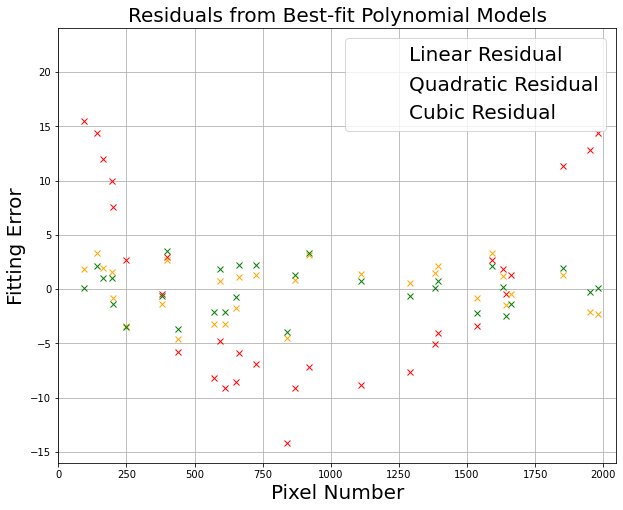

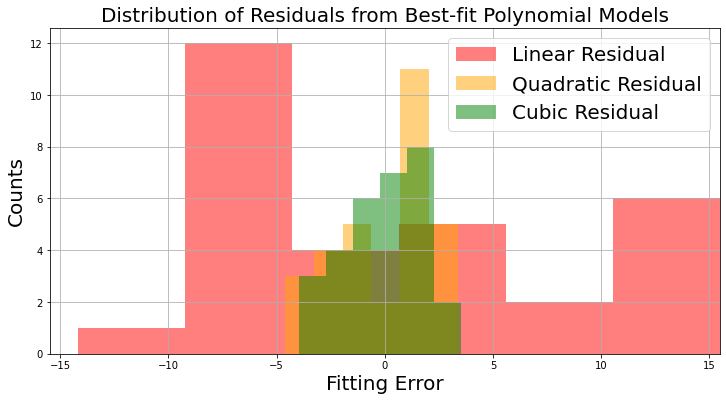

In [4]:
#Plot the residuals of each best-fit model with the true calibration
true_alpha = 0.0 #set to 0 to only plot data

residual_lin = lin_cal[data_x] - data_y
residual_quad = quad_cal[data_x] - data_y
residual_cube = cube_cal[data_x] - data_y

plt.figure(figsize = (10,8))
plt.plot(pixel_number, lin_cal-calibration, '--', color = 'red',
         alpha = true_alpha, label = 'Linear Residual')
plt.plot(pixel_number, quad_cal-calibration, '--', color = 'orange',
         alpha = true_alpha, label = 'Quadratic Residual')
plt.plot(pixel_number, cube_cal-calibration, '--', color = 'green',
         alpha = true_alpha, label = 'Cubic Residual')

plt.plot(data_x, residual_lin, 'x', color = 'red')
plt.plot(data_x, residual_quad, 'x', color = 'orange')
plt.plot(data_x, residual_cube, 'x', color = 'green')

plt.grid()
plt.xlabel("Pixel Number", size = 20)
plt.ylabel("Fitting Error", size = 20)
plt.title("Residuals from Best-fit Polynomial Models", size = 20)
plt.legend(prop={'size': 20})
plt.xlim(0, 2048)
plt.show()

plt.figure(figsize=(12,6))
plt.hist(residual_lin, bins = "sturges", 
         alpha = 0.5, color = 'red', label = 'Linear Residual')
plt.hist(residual_quad, bins = "sturges", 
         alpha = 0.5, color = 'orange', label = 'Quadratic Residual')
plt.hist(residual_cube, bins = "sturges", 
         alpha = 0.5, color = 'green', label = 'Cubic Residual')
plt.grid()
plt.legend(prop={'size': 20})
plt.xlabel("Fitting Error", size = 20)
plt.ylabel("Counts", size = 20)
plt.title("Distribution of Residuals from Best-fit Polynomial Models", size = 20)
plt.xlim(-1*np.max(np.abs(residual_lin)), np.max(np.abs(residual_lin)))
plt.show()




In [8]:
def get_cov(X_model, beta, y):

    #Here is how you find the error on the fit parameters for OLS
    #Here is a reference for the derivation: 
    # https://stats.stackexchange.com/questions/109846/the-variance-covariance-matrix-of-the-least-squares-parameter-estimation
    cov = np.linalg.inv(X_model.T@X_model)*np.var(X_model@beta - y)
    err = np.sqrt(np.diag(cov))
    return cov, err

models = [X_lin, X_quad, X_cube]
betas = [beta_lin, beta_quad, beta_cube]

for i in range(3):
    cov, err = get_cov(models[i], betas[i], data_y)
    str_list = [f"{betas[i][j]:.1E}+/-{err[j]:.0E} x^{len(betas[i])-j-1} " for j in range(len(betas[i]))]
    nice_poly_str = "".join(str_list)
    nice_poly_str = nice_poly_str.replace("^1", "")
    nice_poly_str =nice_poly_str.replace("x^0", "")  
    print(nice_poly_str)


9.5E-02+/-3E-03 x 3.4E+02+/-3E+00  
-2.9E-05+/-1E-06 x^2 1.5E-01+/-3E-03 x 3.3E+02+/-1E+00  
7.3E-09+/-2E-09 x^3 -5.1E-05+/-7E-06 x^2 1.7E-01+/-6E-03 x 3.2E+02+/-2E+00  
